# **2026-2 · TÉCNICAS AVANZADAS DE DATA MINING Y SISTEMAS INTELIGENTES (INF659)**
## **Examen Parcial — (3 horas)**

### Descripción de la tarea
El objetivo es predecir si un paciente presenta rastros de neumonía asociada a COVID-19 a partir de **tomografías computarizadas (TC) de pulmón en 3D**. El dataset contiene volúmenes de TC anonimizados con hallazgos anormales (COVID) y normales.

**Dataset (fuente):** https://www.medrxiv.org/content/10.1101/2020.05.20.20100362v1
Se usa una porción de **100 volúmenes por clase** (normal / anormal).

>  **diseccione, intervenga, diagnostique y defienda** sus decisiones.

## Reglas del examen

- **Tiempo:** 3 horas, modalidad para casa. Trabajo **individual**.
- **Uso de IA:** está **permitido y se espera** que use asistentes de IA / agentes de código. No es trampa. Pero lea con atención cómo se evalúa.
- **Qué se evalúa:** la comprensión, no la ejecución. Casi todas las preguntas dependen de **los resultados de SU propia corrida** (sus curvas, sus tablas de ablación, sus mapas de calor), que un asistente de IA no puede conocer por usted.
- **Video de sustentación (OBLIGATORIO):** suba un video de **máximo 10 minutos** explicando su solución: sus decisiones de diseño, sus resultados de ablación, su análisis de transfer learning, la interpretación de sus Grad-CAM y su diagnóstico. **Los puntos de cada parte se acreditan únicamente si usted puede explicar ese trabajo en el video.** Si no sabe explicar por qué algo está en su código, no recibe el puntaje.
- **Cuaderno de decisiones:** en cada parte hay un espacio para registrar *por qué* tomó cada decisión. Un asistente ejecuta; su justificación demuestra que usted dirigió.
- **Honestidad:** reporte también **lo que NO funcionó**. Un resultado negativo bien analizado vale más que un número inflado.
- **Reproducibilidad:** no modifique las semillas fijadas. Si reduce resolución/épocas para ganar tiempo, decláreo y justifíquelo.
- **Entrega:** este notebook ejecutado + el enlace al video. Total: **20 puntos**.

### Declaración de uso de IA *(obligatoria — complete antes de entregar)*

- Herramienta(s): Claude (asistente de chat de Anthropic).
- Para qué la usé: Para generar el código de las celdas (modelo base, bloque residual 3D, variante con GAP, funciones `entrenar` y `evaluar`, transfer learning slice-wise con ResNet50, Grad-CAM 3D, intervalo de Wilson y métricas clínicas), para depurar errores al correrlo en Colab (imports faltantes y la pérdida de la forma estática en `tf.numpy_function`, que corregí con `set_shape`), y para redactar borradores de los cuadernos de decisiones a partir de los resultados que yo le entregué (logs, `summary()`, curvas, matrices de confusión y mapas de calor). Ejecuté yo todo el código en Colab y las cifras salen de mis corridas.
- Qué partes resolví/decidí yo directamente: Ejecuté todo en Colab (GPU T4) sin modificar las semillas. Se me cerró la sesión durante el examen y perdí variables y checkpoints, así que decidí volver a correr todo con 10 épocas en todas las variantes para que la comparación fuera justa. Me apoyé en una corrida previa de 30 épocas, donde la base alcanzó su mejor `val_acc` en la época 9. Lo declaro como limitación: con 10 épocas el sobreajuste se ve menos y GAP queda penalizado, porque en 30 épocas su mejor época fue la 14. Decidí documentar la variante residual como intento fallido (loss fija en 0,693) y no repetirla, subir el lr de feature extraction a 1e-3 por tener solo 2 049 parámetros entrenables, y hacer Grad-CAM sobre el modelo base declarando que no es el mejor modelo global. Revisé y ajusté los textos de cada parte para que coincidieran con mis resultados.
- Conocimientos del curso que apliqué:
  - **Regularización y BatchNorm (S4):** Dropout 0,3 y BatchNorm en el modelo base, y el efecto de `batch_size=2` sobre BatchNorm (estadísticas por batch vs medias móviles) para interpretar el `val_acc` = 0,50 de las primeras épocas.
  - **Optimización (S4):** Adam con `ExponentialDecay`, sabiendo que `decay_steps` se mide en pasos (85 = una época con batch 2), por lo que a la época 10 el lr queda en ≈35 %.
  - **Sobreajuste y early stopping:** lectura de las curvas train/val, brecha entre ambas, `EarlyStopping` sobre `val_acc` y checkpoint del mejor modelo.
  - **CNN (S5):** conteo de parámetros por bloque con (k³·C_in + 1)·C_out, que mostró que el `Flatten` concentra el 98 %, y GAP y bloques residuales F(x)+x con proyección 1×1×1 como alternativas.
  - **Transfer learning (S6):** feature extraction vs fine-tuning con lr menor, el mismo preprocesamiento que el modelo origen y el domain gap entre ImageNet y TC.
  - **Métricas (Unidad 5):** accuracy vs recall, F1 y AUC según el costo de un falso negativo, e intervalo de confianza con solo 30 volúmenes de test.

### Enlace al video de sustentación (máx. 10 min)

**URL del Drive con el video:** `https://drive.google.com/drive/folders/1kmV8cmbtXrISCgoCrffUmQ6W_w73bvvU?usp=drive_link`

In [ ]:
import tensorflow as tf

from tensorflow.keras.layers import (Input, Conv3D, MaxPool3D, BatchNormalization, Flatten, Dense, Dropout,
                                     Add, Activation, GlobalAveragePooling3D) # Capas

from tensorflow.keras import Model
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K

tf.random.set_seed(0) # No modificar esta línea
import numpy as np
np.random.seed(0)      # No modificar esta línea

In [ ]:
import os
import nibabel as nib
from scipy import ndimage
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline

---
## Carga y preprocesamiento de datos *(provisto — no es lo que se evalúa)*

Las TC están en formato Nifti (`.nii`), con intensidades en unidades Hounsfield (HU), rango [-1024, 2000+]. Se recorta a [-1000, 400] y se normaliza a [0, 1]; cada volumen se redimensiona a (128, 128, 64).

In [ ]:
!git clone https://github.com/iapucp/CT-Scans-100-samples.git
%mv CT-Scans-100-samples/CT-Normal /content/CT-Normal
%mv CT-Scans-100-samples/CT-Abnormal /content/CT-Abnormal
%rm -rf CT-Scans-100-samples/

Cloning into 'CT-Scans-100-samples'...
remote: Enumerating objects: 204, done.
remote: Total 204 (delta 0), reused 0 (delta 0), pack-reused 204 (from 1)
Receiving objects: 100% (204/204), 1.96 GiB | 28.59 MiB/s, done.
Updating files: 100% (200/200), done.


In [ ]:
normal_scan_paths   = ["/content/CT-Normal/"   + x for x in os.listdir("CT-Normal")]
abnormal_scan_paths = ["/content/CT-Abnormal/" + x for x in os.listdir("CT-Abnormal")]
print("Normal:",   len(normal_scan_paths))
print("Abnormal:", len(abnormal_scan_paths))

Normal: 101
Abnormal: 101


In [ ]:
def normalize_scan(scan, min=-1000, max=400):
  scan[scan < min] = min
  scan[scan > max] = max
  scan = (scan - min) / (max - min)
  return scan.astype("float32")

def resize_scan(scan, w, h, d):
  cw, ch, cd = scan.shape[0], scan.shape[1], scan.shape[-1]
  scan = ndimage.rotate(scan, 90, reshape=False)
  scan = ndimage.zoom(scan, (w/cw, h/ch, d/cd), order=1)
  return scan

def preprocess_scan(path, w, h, d):
  scan = nib.load(path).get_fdata()
  return normalize_scan(resize_scan(scan, w, h, d))

width, height, depth = 128, 128, 64

In [ ]:
%%time
# Filtramos las listas de rutas para asegurarnos de que solo procesamos archivos Nifti (.nii o .nii.gz)
normal_paths_filtered = [p for p in normal_scan_paths if p.endswith('.nii') or p.endswith('.nii.gz')]
abnormal_paths_filtered = [p for p in abnormal_scan_paths if p.endswith('.nii') or p.endswith('.nii.gz')]

normal_scans   = np.array([preprocess_scan(p, width, height, depth) for p in normal_paths_filtered])
abnormal_scans = np.array([preprocess_scan(p, width, height, depth) for p in abnormal_paths_filtered])

normal_labels   = np.zeros(normal_scans.shape[0],   dtype=int)
abnormal_labels = np.ones(abnormal_scans.shape[0],  dtype=int)

scans  = np.concatenate([normal_scans,  abnormal_scans],  axis=0)
labels = np.concatenate([normal_labels, abnormal_labels], axis=0)
del normal_scans, abnormal_scans, normal_labels, abnormal_labels

CPU times: user 6min 37s, sys: 15.9 s, total: 6min 52s
Wall time: 6min 52s


In [ ]:
if 'scans' in locals() or 'scans' in globals():
    x_train, x_test, y_train, y_test = train_test_split(
        scans, labels, test_size=0.15, random_state=0, stratify=labels)
    del scans
    print("Partición creada de manera exitosa.")
else:
    print("La partición ya fue creada y la variable 'scans' ya se liberó de la memoria.")

print("Dimensiones del dataset:")
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test:", x_test.shape, "y_test:", y_test.shape)

Partición creada de manera exitosa.
Dimensiones del dataset:
x_train: (170, 128, 128, 64) y_train: (170,)
x_test: (30, 128, 128, 64) y_test: (30,)


In [ ]:
from random import choice, seed
seed(0)

@tf.function
def rotate(scan):
  def scipy_rotate(scan):
    angle = choice([-20, -10, -5, 5, 10, 20])
    scan = ndimage.rotate(scan, angle, reshape=False)
    scan[scan < 0] = 0; scan[scan > 1] = 1
    return scan
  return tf.numpy_function(scipy_rotate, [scan], tf.float32)

def train_aug(scan, label):
  scan = rotate(scan)
  scan.set_shape((width, height, depth))
  return tf.expand_dims(scan, axis=3), label

def test_aug(scan, label):
  return tf.expand_dims(scan, axis=3), label

batch_size = 2 # (preste atención a este valor — se le preguntará por él)
ds_train = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(len(x_train)).map(train_aug).batch(batch_size).prefetch(2)
ds_test  = tf.data.Dataset.from_tensor_slices((x_test,  y_test )).map(test_aug).batch(batch_size).prefetch(2)

In [ ]:
def show_results(log):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,4))
  ax1.plot(log.history['loss'], label='train'); ax1.plot(log.history['val_loss'], label='val')
  ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.legend()
  ax2.plot(log.history['acc'], label='train'); ax2.plot(log.history['val_acc'], label='val')
  ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy'); ax2.legend()
  plt.show()

---
## P1 — Línea base e instrumentación **(3 puntos)**

Construya un modelo **base** sencillo (unas pocas capas `Conv3D` + `pooling` + una cabeza densa → `sigmoid`).

**Antes de entrenar, responda (predicción):**
1. Con ~170 volúmenes de entrenamiento y `batch_size=2`, ¿espera sobreajuste? Describa **cómo predice** que se verá la brecha entre `train` y `val` (loss y accuracy).

Luego entrene, muestre las curvas con `show_results`, e **instrumente** el modelo:
2. Reporte el **número total de parámetros** y cuántos aporta cada bloque (puede usar `model.summary()`).
3. Compare su **predicción** del punto 1 con lo que **realmente** ocurrió. ¿Acertó? Si no, ¿por qué cree que se equivocó?

In [ ]:
K.clear_session()
inputs = Input(shape=(width, height, depth, 1))

# TODO (P1): construya aquí su modelo base (pocas capas convolucionales + cabeza densa)
x = Conv3D(16, 3, activation="relu")(inputs); x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = Conv3D(32, 3, activation="relu")(x);      x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = Conv3D(32, 3, activation="relu")(x);      x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = Flatten()(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(units=1, activation="sigmoid")(x)
model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 64,   │             0 │
│                                 │ 1)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 126, 126, 62,   │           448 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 63, 63, 31, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 63, 63, 31, 16) │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 61, 61, 29, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 30, 30, 14, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 30, 14, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 28, 28, 12, 32) │        27,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 14, 14, 6, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 6, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 37632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,408,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,450,881 (9.35 MB)

 Trainable params: 2,450,721 (9.35 MB)

 Non-trainable params: 160 (640.00 B)

In [ ]:
print(ds_train.element_spec)
print(ds_test.element_spec)

(TensorSpec(shape=(None, 128, 128, 64, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
(TensorSpec(shape=(None, 128, 128, 64, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 46s 329ms/step - acc: 0.5647 - loss: 1.2875 - val_acc: 0.5000 - val_loss: 1.0243
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 328ms/step - acc: 0.6176 - loss: 0.7181 - val_acc: 0.5000 - val_loss: 1.0729
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 342ms/step - acc: 0.6235 - loss: 0.6417 - val_acc: 0.5000 - val_loss: 1.0277
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 333ms/step - acc: 0.7059 - loss: 0.5696 - val_acc: 0.5000 - val_loss: 1.2147
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 338ms/step - acc: 0.6824 - loss: 0.5819 - val_acc: 0.6000 - val_loss: 0.6295
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 27s 322ms/step - acc: 0.7235 - loss: 0.5150 - val_acc: 0.6667 - val_loss: 0.5771
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 337ms/step - acc: 0.7412 - loss: 0.4928 - val_acc: 0.7000 - val_loss: 0.5120
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 326ms/step - acc: 0.7706 - loss: 0.4512 - val_acc: 0.7000 - val_loss: 0.5580
Epoch 9/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 324ms/

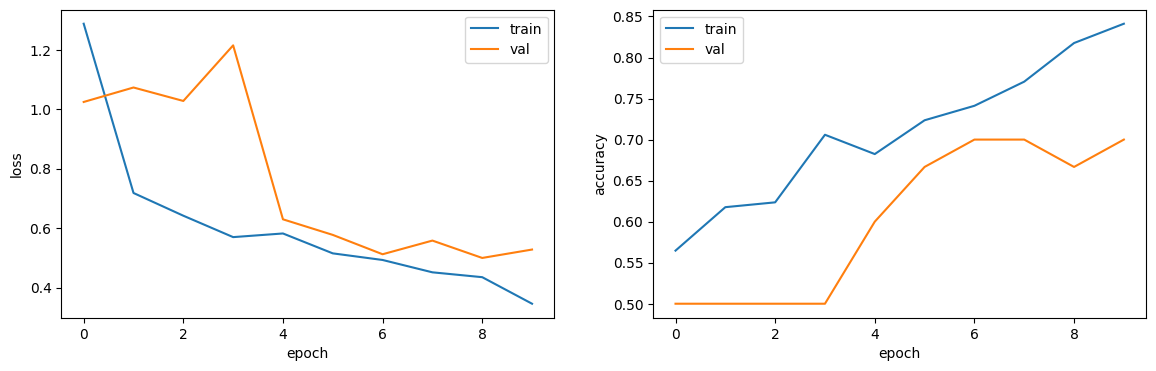

In [ ]:
initial_learning_rate = 0.0001
lr_schedule = ExponentialDecay(initial_learning_rate, decay_steps=85, decay_rate=0.90) # TODO

model.compile(optimizer=Adam(learning_rate=lr_schedule),
              loss="binary_crossentropy", metrics=["acc"])

checkpoint     = ModelCheckpoint("base-{epoch:02d}-{val_acc:.3f}.weights.h5",
                                 monitor="val_acc", mode="max", save_best_only=True, save_weights_only=True)
early_stopping = EarlyStopping(monitor="val_acc", patience=8, mode="max") # TODO
callbacks = [checkpoint, early_stopping]

log = model.fit(ds_train, epochs=10, callbacks=callbacks, validation_data=ds_test) # TODO
show_results(log)

**P1 — Sus respuestas / cuaderno de decisiones**

- **Predicción (antes de entrenar) →** Esperaba sobreajuste, porque hay pocos datos (170 volúmenes de entrenamiento) y muchos parámetros. En accuracy, que la de train subiera mucho más que la de validación (brecha de al menos 10 puntos). En loss, que la de train bajara de forma continua mientras la de validación llegara a un mínimo y luego subiera. Hice esta predicción antes de la primera corrida (30 épocas). Después, por tiempo, repetí con 10 épocas.

- **Parámetros totales y por bloque →** El modelo tiene 2 450 881 parámetros (160 no entrenables, de BatchNorm). Bloque 1 = 512, bloque 2 = 13 984 y bloque 3 = 27 808. Casi todo está en la parte densa (Flatten + Dense + salida) con 2 408 577, el 98 % del total. Esto pasa porque `Flatten` convierte el volumen en 37 632 valores y cada uno se conecta a las 64 neuronas de `Dense(64)`.

- **Predicción vs realidad (¿acertó? ¿por qué?) →** Acerté en parte. El sobreajuste ya aparece: en la época 10 la accuracy de train es 0,841 y la de validación 0,700 (14 puntos), y la loss de train es 0,346 contra 0,528 en validación. La brecha real probablemente es algo mayor, porque train se mide con Dropout y augmentation activos. Lo que no se vio fue el patrón de la loss que esperaba: la `val_loss` bajó hasta ≈0,50 (época 9) y en la 10 subió a 0,528, un solo punto que no basta para hablar de mínimo. Tampoco intervino `EarlyStopping`: el mejor `val_acc` fue 0,700 en la época 7 y con patience 8 no alcanza a cumplirse en 10 épocas. Con más épocas probablemente seguiría sobreajustando, pero no lo verifiqué con esta corrida. Lo que no anticipé fue que en las épocas 1 a 4 el `val_acc` se quedara en 0,50 con una `val_loss` de 1,02 a 1,21, que es peor que adivinar (ln 2 ≈ 0,69) y mayor que la de train. Eso no es sobreajuste, sino una diferencia entre entrenamiento e inferencia. Mi explicación es BatchNorm con batch 2: las estadísticas por batch son ruidosas y las medias móviles de validación tardan en ajustarse. No lo comprobé.

- **Decisiones de diseño del modelo base →** Tres bloques Conv3D + MaxPool3D + BatchNorm con 16, 32 y 32 filtros, para mantener el modelo pequeño y poder compararlo con las variantes de P2. Después van Flatten, Dense(64), Dropout(0,3) para reducir el sobreajuste y una salida sigmoide. Usé Adam con lr inicial 1e-4 y decay exponencial de 0,90 por época (`decay_steps=85`, una época con batch 2), así que a la época 10 el lr ha caído a ≈35 %. Entrené solo 10 épocas por tiempo, y con ese tope `EarlyStopping` (patience 8) casi no puede actuar. Limitación: el conjunto de test se usa también como validación para elegir el mejor checkpoint, así que el `val_acc` es algo optimista, y con solo 30 volúmenes cada error mueve la métrica 3,3 puntos.

---
## P2 — Intervención arquitectónica y ablación **(6 puntos)**

Compare **tres variantes** de arquitectura sobre el mismo problema. Para **cada una**, escriba una **hipótesis antes de correr**, entrénela y registre sus números en la tabla.

- **(a) Base** — su modelo de P1 con cabeza densa.
- **(b) Conexiones residuales** — introduzca bloques residuales 3D (estilo ResNet): `salida = F(x) + x`. Explique qué resuelven aquí.
- **(c) Fully-convolutional con Global Average Pooling** — elimine las densas finales y use `GlobalAveragePooling3D` antes de la salida (estilo *Network in Network* / GoogLeNet).

Lo que se evalúa es la **tabla completa con SUS resultados** y su **explicación de los deltas**, no que cada variante alcance el mejor accuracy.

**Recuerde:** no es lo mismo una capa convolucional con 1024 filtros que con 128. Controle los demás factores para que la comparación sea justa.

In [ ]:
import glob
resultados = {}

def entrenar(modelo, nombre, epochs=10):
    # Mismas condiciones que P1: Adam, mismo ExponentialDecay, misma EarlyStopping
    lr = ExponentialDecay(0.0001, decay_steps=85, decay_rate=0.90)
    modelo.compile(optimizer=Adam(learning_rate=lr),
                   loss="binary_crossentropy", metrics=["acc"])
    ckpt = ModelCheckpoint(f"{nombre}.weights.h5", monitor="val_acc", mode="max",
                           save_best_only=True, save_weights_only=True)
    es = EarlyStopping(monitor="val_acc", patience=8, mode="max")
    log = modelo.fit(ds_train, epochs=epochs, callbacks=[ckpt, es], validation_data=ds_test)
    show_results(log)
    return log

def evaluar(modelo, ruta_pesos, log, nombre):
    modelo.load_weights(ruta_pesos)   # mejor checkpoint, no la última época
    prob = modelo.predict(ds_test, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    resultados[nombre] = {
        "params": modelo.count_params(),
        "val_acc": float((pred == y_test).mean()),
        "val_f1": float(f1_score(y_test, pred)),
        "epocas": len(log.history["loss"]),
        "mejor_epoca": int(np.argmax(log.history["val_acc"]) + 1),
    }
    print(nombre, resultados[nombre])
    print(confusion_matrix(y_test, pred))

# (a) Base: usa el modelo y el log de P1 (si no reiniciaste el entorno)
mejor = int(np.argmax(log.history["val_acc"]) + 1)
ruta_base = max(glob.glob(f"base-{mejor:02d}-*.weights.h5"), key=os.path.getmtime)
print(ruta_base)   # debe coincidir con la mejor época de tu log de P1
evaluar(model, ruta_base, log, "a_base")

base-07-0.700.weights.h5
a_base {'params': 2450881, 'val_acc': 0.7, 'val_f1': 0.7428571428571429, 'epocas': 10, 'mejor_epoca': 7}
[[ 8  7]
 [ 2 13]]


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 64, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 126, 126,  │        448 │ input_layer[0][0] │
│                     │ 62, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d       │ (None, 63, 63,    │          0 │ conv3d[0][0]      │
│ (MaxPooling3D)      │ 31, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 63, 63,    │         64 │ max_pooling3d[0]… │
│ (BatchNormalizatio… │ 31, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 63, 63,    │     13,856 │ batch_normalizat… │
│                     │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 63, 63,    │        128 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 63, 63,    │          0 │ batch_normalizat… │
│ (Activation)        │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 63, 63,    │     27,680 │ activation[0][0]  │
│                     │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 63, 63,    │        128 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 63, 63,    │        544 │ batch_normalizat… │
│                     │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 63, 63,    │          0 │ batch_normalizat… │
│                     │ 31, 32)           │            │ conv3d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 63, 63,    │          0 │ add[0][0]         │
│ (Activation)        │ 31, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_1     │ (None, 31, 31,    │          0 │ activation_1[0][… │
│ (MaxPooling3D)      │ 15, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_4 (Conv3D)   │ (None, 31, 31,    │     27,680 │ max_pooling3d_1[… │
│                     │ 15, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 31, 31,    │        128 │ conv3d_4[0][0]    │
│ (BatchNormalizatio… │ 15, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 31, 31,    │          0 │ batch_normalizat… │
│ (Activation)        │ 15, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_5 (Conv3D)   │ (None, 31, 31,    │     27,680 │ activation_2[0][

 Total params: 3,324,193 (12.68 MB)

 Trainable params: 3,323,905 (12.68 MB)

 Non-trainable params: 288 (1.12 KB)

Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 39s 345ms/step - acc: 0.5059 - loss: 2.0675 - val_acc: 0.5000 - val_loss: 0.6949
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 342ms/step - acc: 0.4941 - loss: 0.7307 - val_acc: 0.5000 - val_loss: 0.6962
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 330ms/step - acc: 0.5000 - loss: 0.6932 - val_acc: 0.4333 - val_loss: 0.6949
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 331ms/step - acc: 0.5118 - loss: 0.7050 - val_acc: 0.5000 - val_loss: 0.6931
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 336ms/step - acc: 0.5000 - loss: 0.6932 - val_acc: 0.5000 - val_loss: 0.6931
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 328ms/step - acc: 0.5000 - loss: 0.6932 - val_acc: 0.5000 - val_loss: 0.6931
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 330ms/step - acc: 0.5000 - loss: 0.6932 - val_acc: 0.5000 - val_loss: 0.6931
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 336ms/step - acc: 0.5000 - loss: 0.6932 - val_acc: 0.5000 - val_loss: 0.6931
Epoch 9/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 328ms/

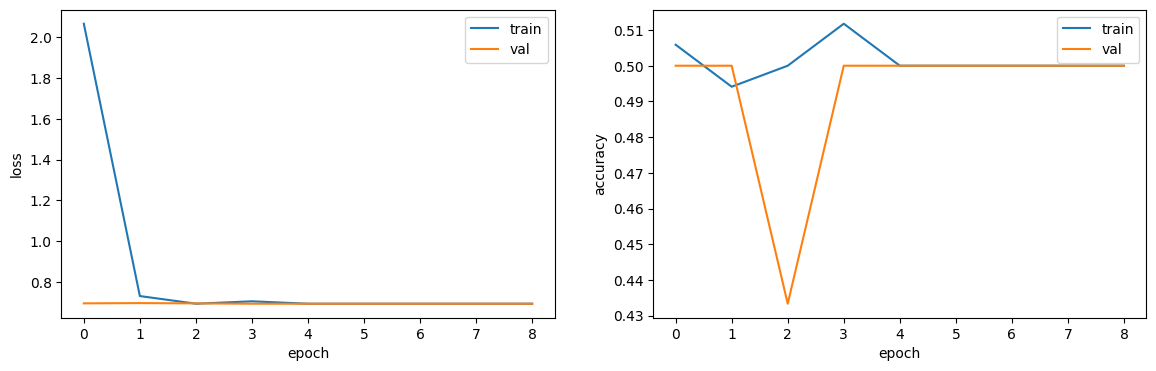

b_residual {'params': 3324193, 'val_acc': 0.5, 'val_f1': 0.0, 'epocas': 9, 'mejor_epoca': 1}
[[15  0]
 [15  0]]


In [ ]:
def residual_block_3d(x, filters):
    atajo = x
    if x.shape[-1] != filters:                       # proyección 1x1x1 si cambian los canales
        atajo = Conv3D(filters, 1, padding="same")(atajo)
    y = Conv3D(filters, 3, padding="same")(x)
    y = BatchNormalization()(y)
    y = Activation("relu")(y)
    y = Conv3D(filters, 3, padding="same")(y)
    y = BatchNormalization()(y)
    y = Add()([y, atajo])                            # salida = F(x) + x
    return Activation("relu")(y)

K.clear_session()
inputs = Input(shape=(width, height, depth, 1))
x = Conv3D(16, 3, activation="relu")(inputs); x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = residual_block_3d(x, 32); x = MaxPool3D(2)(x)
x = residual_block_3d(x, 32); x = MaxPool3D(2)(x)
x = Flatten()(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)
outputs = Dense(1, activation="sigmoid")(x)
model_res = Model(inputs, outputs)
model_res.summary()

log_res = entrenar(model_res, "res")
evaluar(model_res, "res.weights.h5", log_res, "b_residual")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 64,   │             0 │
│                                 │ 1)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 126, 126, 62,   │           448 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 63, 63, 31, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 63, 63, 31, 16) │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 61, 61, 29, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 30, 30, 14, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 30, 14, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 28, 28, 12, 32) │        27,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 14, 14, 6, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 6, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,337 (165.38 KB)

 Trainable params: 42,177 (164.75 KB)

 Non-trainable params: 160 (640.00 B)

Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 35s 330ms/step - acc: 0.5765 - loss: 0.6683 - val_acc: 0.5000 - val_loss: 0.9643
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 325ms/step - acc: 0.5765 - loss: 0.6490 - val_acc: 0.5000 - val_loss: 1.5471
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 333ms/step - acc: 0.6588 - loss: 0.6447 - val_acc: 0.5000 - val_loss: 1.9452
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 330ms/step - acc: 0.6353 - loss: 0.6528 - val_acc: 0.5000 - val_loss: 1.7534
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 332ms/step - acc: 0.6118 - loss: 0.6335 - val_acc: 0.5000 - val_loss: 1.6884
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 328ms/step - acc: 0.5882 - loss: 0.6539 - val_acc: 0.5000 - val_loss: 1.0423
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 343ms/step - acc: 0.6471 - loss: 0.6323 - val_acc: 0.5000 - val_loss: 0.9317
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 27s 322ms/step - acc: 0.6353 - loss: 0.6182 - val_acc: 0.6667 - val_loss: 0.6789
Epoch 9/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 324ms/

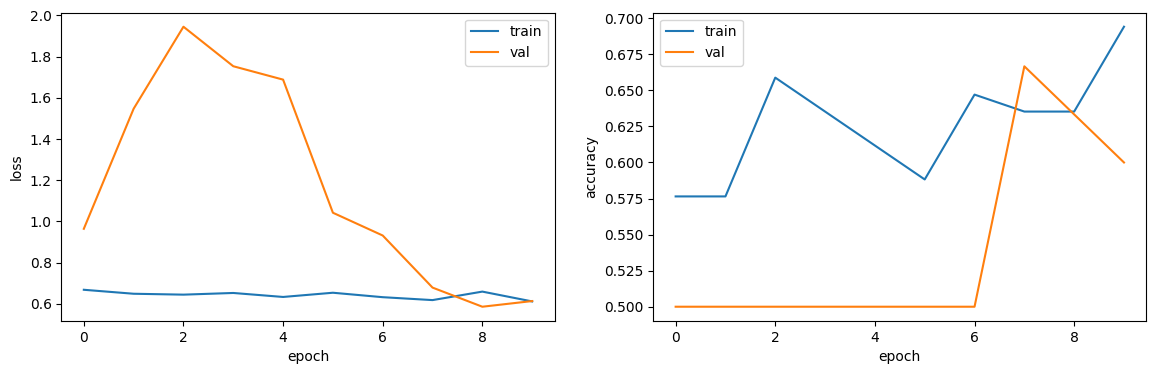

c_gap {'params': 42337, 'val_acc': 0.6666666666666666, 'val_f1': 0.7368421052631579, 'epocas': 10, 'mejor_epoca': 8}
[[ 6  9]
 [ 1 14]]


In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling3D

K.clear_session()
inputs = Input(shape=(width, height, depth, 1))
x = Conv3D(16, 3, activation="relu")(inputs); x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = Conv3D(32, 3, activation="relu")(x);      x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = Conv3D(32, 3, activation="relu")(x);      x = MaxPool3D(2)(x); x = BatchNormalization()(x)
x = GlobalAveragePooling3D()(x)
outputs = Dense(1, activation="sigmoid")(x)
model_gap = Model(inputs, outputs)
model_gap.summary()

log_gap = entrenar(model_gap, "gap")
evaluar(model_gap, "gap.weights.h5", log_gap, "c_gap")

**P2 — Tabla de ablación (complete con SUS resultados)**

| Variante | #Parámetros | Val. accuracy | Val. F1 | Épocas (early stop) | Observación clave |
|---|---|---|---|---|---|
| (a) Base (densa) | 2 450 881 | 0,700 | 0,743 | 10 (mejor: 7) | Sobreajuste incipiente: train 0,841 vs val 0,700. Marca 7 de 15 normales como anormales. |
| (b) Residual 3D | 3 324 193 | 0,500 | 0,000 | 9 (mejor: 1) | No aprendió: loss fija en 0,693 y clasifica todo como normal. |
| (c) GAP (fully-conv) | 42 337 | 0,667 | 0,737 | 10 (mejor: 8) | Aprende lento: train 0,69 y aún mejorando en la época 10. Marca 9 de 15 normales como anormales. |

**Análisis (cuaderno de decisiones):**
- Hipótesis previa de cada variante → (a) Sobreajusta: el 98 % de sus parámetros está en la cabeza densa. (b) Mejora pequeña o nula: la suma F(x)+x da al gradiente un camino directo a las primeras capas, pero eso importa en redes profundas y aquí hay solo 2 bloques. (c) Menos sobreajuste por tener ~58 veces menos parámetros, pero con riesgo de subajuste.
- ¿Por qué cambian los resultados entre (a), (b) y (c)? → Las tres variantes usan los mismos filtros (16/32/32), lr, épocas y callbacks, así que solo cambia la arquitectura. (b) no aprendió: la loss de train empezó en 2,07 y desde la época 3 quedó en 0,693 = ln 2, es decir, una salida constante de 0,5 (matriz 15/0/15/0). Ya me había pasado en la corrida de 30 épocas, así que no parece mala suerte con la semilla. Mi hipótesis, sin comprobar, es que mi bloque termina en ReLU + pooling sin BatchNorm, así que a `Dense(64)` le llegan 50 400 valores sin normalizar; la base recibe 37 632 ya normalizados (en (b) son más porque el padding `same` no reduce el tamaño). Por eso este resultado no dice nada contra las residuales en sí. En (c), GAP promedia cada mapa en un valor y reemplaza a `Flatten` + `Dense`: pasa de 2,45 M a 42 mil parámetros y deja de sobreajustar (train y val loss en 0,61), pero aprende lento: `val_acc` = 0,50 hasta la época 7 y la `val_loss` aún bajaba en la 10. Detecta 14 de 15 anormales, pero con 9 falsos positivos.
- ¿Cuál elegiría y por qué? → La base (a), porque tiene la mayor accuracy y F1. Con 30 volúmenes y una sola corrida por variante, la diferencia con (c) es un solo error (21 vs 20 aciertos), así que es ruido y no puedo afirmar que (a) sea mejor. Elijo (a) como mejor modelo desde cero para la comparación de P3. (c) me parece prometedor por su tamaño, pero con más épocas. A (b) no la puedo juzgar hasta corregir su diseño.

---
## P3 — Transfer learning 2D→3D **(4 puntos)**

Los backbones pre-entrenados (ResNet/EfficientNet) son **2D y de ImageNet**; aquí los datos son **3D y de TC médica**. Elija **una** estrategia de adaptación y compárela contra su mejor modelo entrenado desde cero:

- **(i) Slice-wise:** aplique un backbone 2D pre-entrenado a cada corte (slice) y agregue las características (p. ej. pooling sobre la profundidad), **o**
- **(ii) Inflación 3D:** infle los pesos 2D a kernels 3D.

Para la estrategia elegida, pruebe **feature extraction** (backbone congelado) **vs fine-tuning**.

**Responda:**
1. ¿El transfer learning ayudó frente a entrenar desde cero? Muestre números y discuta el **domain gap** (imágenes naturales → TC).
2. **Trampa de BatchNorm:** con `batch_size=2`, ¿qué problema aparece con las capas de BatchNorm (propias y del backbone pre-entrenado)? ¿Cómo lo maneja?

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Lambda, TimeDistributed, GlobalAveragePooling1D

N_SLICES = 16
PASO = depth // N_SLICES          # 64 // 16 = 4 -> un corte cada 4

def construir_slicewise():
    base = ResNet50(include_top=False, weights="imagenet",
                    input_shape=(height, width, 3), pooling="avg")
    base.trainable = False
    inputs = Input(shape=(width, height, depth, 1))
    # (B,W,H,D,1) -> (B,16,W,H,1): la profundidad pasa a ser el eje "tiempo"
    x = Lambda(lambda t: tf.transpose(t[:, :, :, ::PASO, :], [0, 3, 1, 2, 4]))(inputs)
    # gris -> 3 canales y preprocesamiento de ResNet50 (0-255, media de ImageNet)
    x = Lambda(lambda t: tf.repeat(t * 255.0, 3, axis=-1)
                         - tf.constant([103.939, 116.779, 123.68]))(x)
    x = TimeDistributed(base)(x)            # (B,16,2048)
    x = GlobalAveragePooling1D()(x)         # agrega los cortes -> (B,2048)
    x = Dropout(0.3)(x)
    outputs = Dense(1, activation="sigmoid")(x)
    return Model(inputs, outputs), base

def entrenar_lr(modelo, nombre, lr0, epochs=10):
    lr = ExponentialDecay(lr0, decay_steps=85, decay_rate=0.90)
    modelo.compile(optimizer=Adam(learning_rate=lr),
                   loss="binary_crossentropy", metrics=["acc"])
    ckpt = ModelCheckpoint(f"{nombre}.weights.h5", monitor="val_acc", mode="max",
                           save_best_only=True, save_weights_only=True)
    es = EarlyStopping(monitor="val_acc", patience=8, mode="max")
    log = modelo.fit(ds_train, epochs=epochs, callbacks=[ckpt, es], validation_data=ds_test)
    show_results(log)
    return log

def n_entrenables(modelo):
    return sum(int(np.prod(w.shape)) for w in modelo.trainable_weights)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 64,   │             0 │
│                                 │ 1)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_4 (Lambda)               │ (None, 16, 128, 128,   │             0 │
│                                 │ 1)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_5 (Lambda)               │ (None, 16, 128, 128,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 16, 2048)       │    23,587,712 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Entrenables: 2049
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 197s 849ms/step - acc: 0.5176 - loss: 0.9335 - val_acc: 0.6667 - val_loss: 0.6004
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 350ms/step - acc: 0.6765 - loss: 0.6610 - val_acc: 0.7333 - val_loss: 0.5166
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 332ms/step - acc: 0.6176 - loss: 0.7183 - val_acc: 0.6000 - val_loss: 0.7481
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 334ms/step - acc: 0.6941 - loss: 0.6053 - val_acc: 0.7000 - val_loss: 0.6023
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 362ms/step - acc: 0.6882 - loss: 0.5630 - val_acc: 0.8333 - val_loss: 0.4865
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 334ms/step - acc: 0.6765 - loss: 0.6146 - val_acc: 0.8333 - val_loss: 0.4747
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 345ms/step - acc: 0.6882 - loss: 0.5933 - val_acc: 0.8333 - val_loss: 0.4638
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 355ms/step - acc: 0.7059 - loss: 0.5654 - val_acc: 0.8667 - val_loss: 0.4467
Epoch 9/10
85/85 ━━━━━━━━━━━━

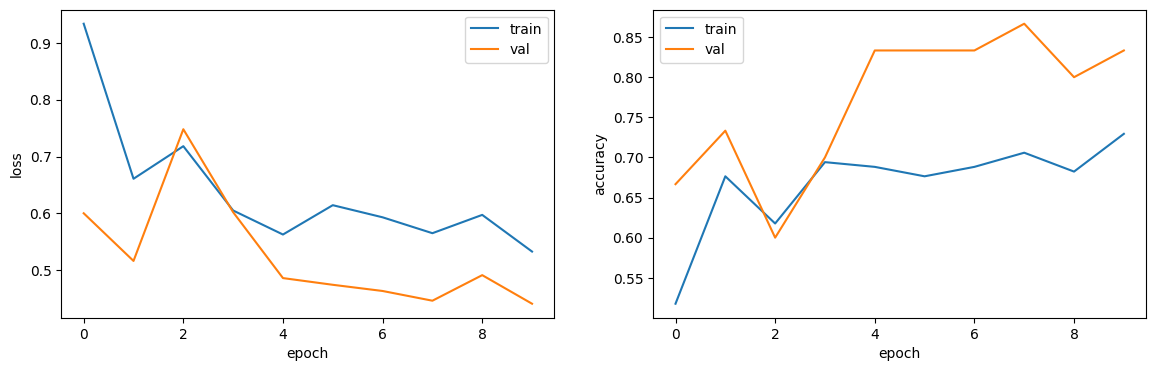

tl_feature_extraction {'params': 23589761, 'val_acc': 0.8666666666666667, 'val_f1': 0.8666666666666667, 'epocas': 10, 'mejor_epoca': 8}
[[13  2]
 [ 2 13]]


In [ ]:
model_fe, base_fe = construir_slicewise()
model_fe.summary()
print("Entrenables:", n_entrenables(model_fe))   # esperado: 2049 (solo la cabeza)

log_fe = entrenar_lr(model_fe, "tl_fe", lr0=1e-3)    # solo la cabeza se entrena; lr mayor por las pocas épocas
evaluar(model_fe, "tl_fe.weights.h5", log_fe, "tl_feature_extraction")

Entrenables: 14955521
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 206s 872ms/step - acc: 0.5353 - loss: 0.7990 - val_acc: 0.6333 - val_loss: 0.6198
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 360ms/step - acc: 0.6353 - loss: 0.6489 - val_acc: 0.7000 - val_loss: 0.5530
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 366ms/step - acc: 0.6941 - loss: 0.5881 - val_acc: 0.8667 - val_loss: 0.4303
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 361ms/step - acc: 0.7000 - loss: 0.5082 - val_acc: 0.9000 - val_loss: 0.3654
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 359ms/step - acc: 0.7706 - loss: 0.4643 - val_acc: 0.9333 - val_loss: 0.4296
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 351ms/step - acc: 0.8176 - loss: 0.4182 - val_acc: 0.7333 - val_loss: 0.4278
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 348ms/step - acc: 0.8529 - loss: 0.4116 - val_acc: 0.7667 - val_loss: 0.3890
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 29s 345ms/step - acc: 0.8765 - loss: 0.3246 - val_acc: 0.8667 - val_loss: 0.3533
Epoch 9/10
85/85 ━━━━━━━━

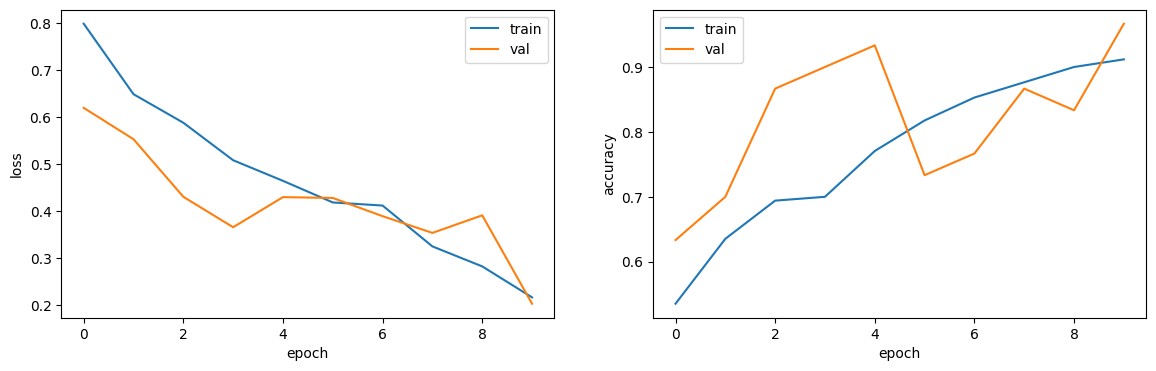

tl_finetuning {'params': 23589761, 'val_acc': 0.9666666666666667, 'val_f1': 0.9655172413793104, 'epocas': 10, 'mejor_epoca': 10}
[[15  0]
 [ 1 14]]


In [ ]:
model_ft, base_ft = construir_slicewise()
model_ft.load_weights("tl_fe.weights.h5")        # parte de la cabeza ya entrenada

base_ft.trainable = True
for capa in base_ft.layers:
    if isinstance(capa, tf.keras.layers.BatchNormalization):
        capa.trainable = False                    # BN siempre congelada (estadísticas de ImageNet)
    else:
        capa.trainable = capa.name.startswith("conv5_")   # solo el último bloque
print("Entrenables:", n_entrenables(model_ft))

log_ft = entrenar_lr(model_ft, "tl_ft", lr0=1e-4)    # 10 veces menor que en feature extraction
evaluar(model_ft, "tl_ft.weights.h5", log_ft, "tl_finetuning")

In [ ]:
for k, v in resultados.items():
    print(f"{k:24s} params={v['params']:>10,}  acc={v['val_acc']:.3f}  f1={v['val_f1']:.3f}  mejor_ep={v['mejor_epoca']}")

a_base                   params= 2,450,881  acc=0.700  f1=0.743  mejor_ep=7
b_residual               params= 3,324,193  acc=0.500  f1=0.000  mejor_ep=1
c_gap                    params=    42,337  acc=0.667  f1=0.737  mejor_ep=8
tl_feature_extraction    params=23,589,761  acc=0.867  f1=0.867  mejor_ep=8
tl_finetuning            params=23,589,761  acc=0.967  f1=0.966  mejor_ep=10


**P3 — Sus respuestas / cuaderno de decisiones**

- **Estrategia elegida y por qué →** Slice-wise con ResNet50 de ImageNet. Tomo 16 de los 64 cortes (uno cada 4) para reducir el costo, replico cada corte a 3 canales con el preprocesamiento de ResNet50, saco 2048 características por corte y las promedio sobre la profundidad (`GlobalAveragePooling1D`) antes de `Dropout(0,3)` y la salida sigmoide. La elegí sobre la inflación 3D porque reutiliza los pesos 2D tal cual, sin reescribir kernels, y ResNet es una arquitectura vista en clase.

- **Feature extraction vs fine-tuning (números) →** Con el backbone congelado entreno solo la cabeza (2 049 de 23,6 M parámetros, lr 1e-3): val_acc 0,867 y F1 0,867 (época 8). En fine-tuning parto de esa cabeza y libero solo el último bloque (`conv5_`, 14,96 M parámetros entrenables) con lr 1e-4: val_acc 0,967 y F1 0,966 (época 10), con 1 falso negativo y 0 falsos positivos. Desde cero, mi mejor modelo (a) tuvo 0,700 y F1 0,743. El fine-tuning fue la mejor época en la última, así que probablemente seguía mejorando. Cambié el lr de feature extraction a 1e-3 (en P1 usé 1e-4) porque solo se entrenan 2 049 parámetros y son 10 épocas.

- **¿Ayudó el transfer learning? Domain gap →** Sí. Feature extraction ya supera al modelo desde cero (26 vs 21 aciertos de 30), y arranca mejor: en la época 1 el `val_acc` fue 0,667, mientras que mi base estuvo en 0,50 las 4 primeras épocas. Esto pasa aunque hay un domain gap claro: ImageNet son fotos a color de objetos, y aquí son cortes de TC en escala de grises replicados a 3 canales. Las características de bajo nivel (bordes, texturas) se transfieren, pero las de alto nivel no son específicas de pulmón, y por eso feature extraction se queda en 0,867 con train acc de solo 0,73. Fine-tuning de `conv5_` adapta esas características a la TC y sube a 0,967. Reservas: es una sola corrida, el test se usa también como validación, y la mejor época se eligió sobre esos mismos 30 volúmenes, así que 0,967 es optimista (la época anterior tuvo 0,833).

- **Manejo de BatchNorm con batch_size=2 →** Con 2 volúmenes por paso, las estadísticas de BatchNorm por batch son ruidosas. En el backbone, los 32 cortes de un paso (2 × 16) vienen de solo 2 pacientes y están muy correlacionados, así que tampoco representan la distribución. Por eso dejé todas las BatchNorm del backbone congeladas, también durante el fine-tuning (`trainable = False`, que fuerza el modo inferencia con las estadísticas de ImageNet). La cabeza no tiene BatchNorm propia. El costo es que esas estadísticas no son las de la TC, y eso forma parte del domain gap. Algo que observé, sin aislarlo: mis modelos desde cero con BatchNorm tuvieron una `val_loss` > 1 en las primeras épocas, y el modelo con transfer learning no (0,60 en la época 1).

---
## P4 — Interpretabilidad: ¿mira el modelo los pulmones? **(3 puntos)**

Implemente **Grad-CAM** (o CAM, si usó la variante con GAP) sobre su mejor modelo y genérelo para:
- **2 volúmenes bien clasificados**, y
- **2 volúmenes mal clasificados**.

Superponga el mapa de calor sobre algunos cortes y **analice**: ¿el modelo atiende al tejido pulmonar / a las lesiones, o a **artefactos espurios** (bordes de la imagen, contorno del cuerpo, fondo)? Conecte con lo visto sobre GAP → mapas de activación de clase.

In [ ]:
def grad_cam_3d(model, volume, last_conv_layer_name, class_index=1):
    # class_index: 1 = anormal (COVID), 0 = normal. Se explica la clase indicada.
    capa = model.get_layer(last_conv_layer_name)
    grad_model = Model(model.inputs, [capa.output, model.output])

    x = tf.convert_to_tensor(volume[np.newaxis, ..., np.newaxis], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(x, training=False)
        score = pred[:, 0] if class_index == 1 else 1.0 - pred[:, 0]
    grads = tape.gradient(score, conv_out)

    pesos = tf.reduce_mean(grads, axis=(0, 1, 2, 3))          # un peso por canal
    cam = tf.reduce_sum(conv_out[0] * pesos, axis=-1)          # combinación ponderada
    cam = tf.nn.relu(cam).numpy()                              # solo lo que aporta a la clase
    cam = cam / (cam.max() + 1e-8)                             # normaliza a [0,1]

    # reescala al tamaño del volumen (128,128,64)
    cam = ndimage.zoom(cam, (width / cam.shape[0], height / cam.shape[1], depth / cam.shape[2]), order=1)
    return cam

Acierto idx=5 real=1 pred=1 p=0.99 corte_max=40 calor_en_borde=11%
Acierto idx=13 real=0 pred=0 p=0.15 corte_max=51 calor_en_borde=52%
Error idx=11 real=0 pred=1 p=0.88 corte_max=51 calor_en_borde=46%
Error idx=2 real=0 pred=1 p=0.77 corte_max=29 calor_en_borde=52%


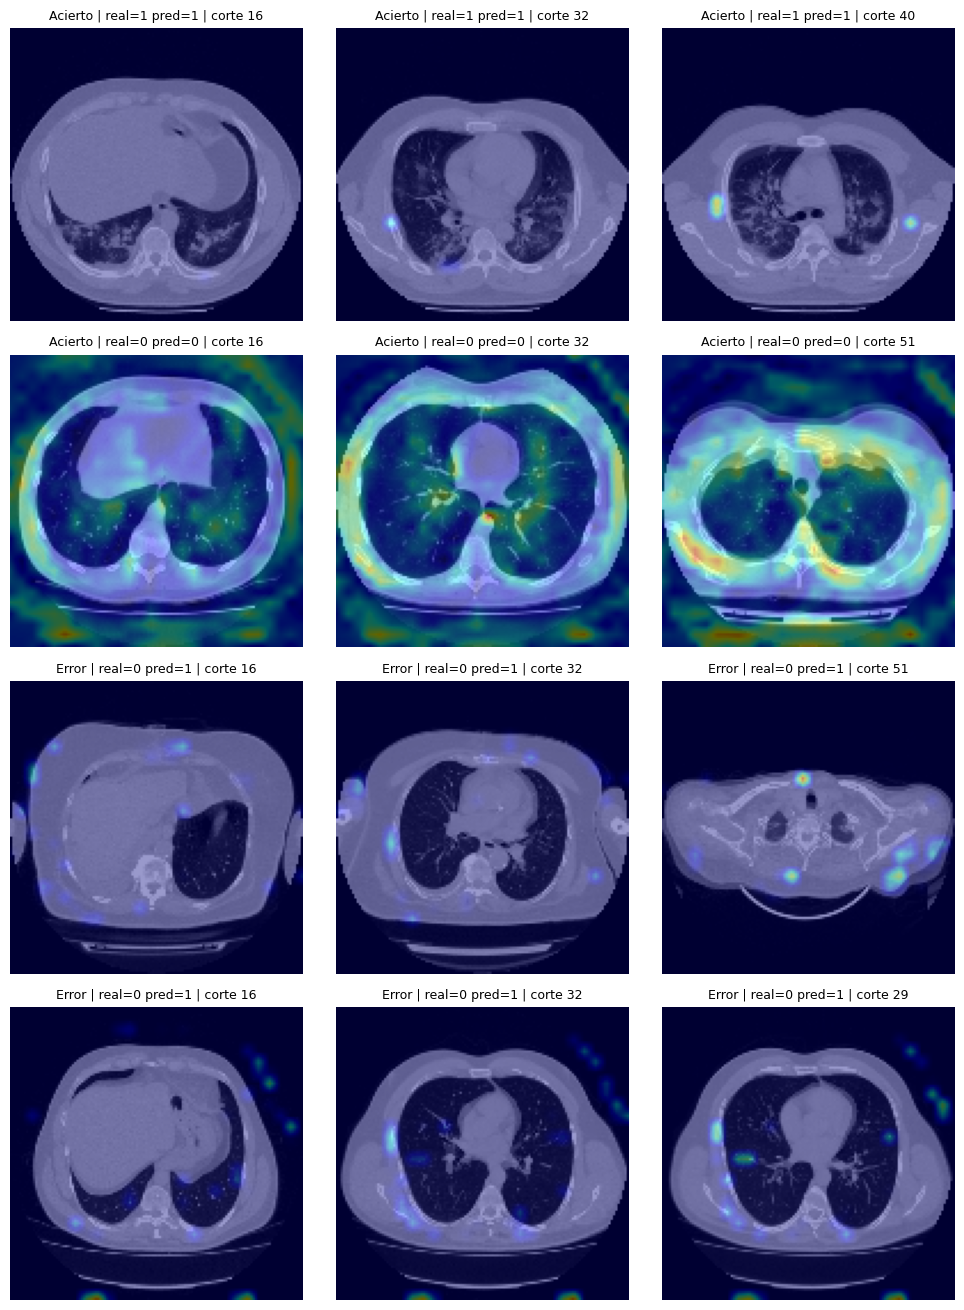

In [ ]:
# El modelo (a) ya tiene cargados los pesos de su mejor época (por evaluar en P2)
ULTIMA_CONV = "conv3d_2"      # última capa convolucional del modelo base

prob = model.predict(ds_test, verbose=0).ravel()
pred = (prob > 0.5).astype(int)
conf = np.where(pred == 1, prob, 1 - prob)           # confianza en la clase predicha

ok  = np.where(pred == y_test)[0]
mal = np.where(pred != y_test)[0]
def top(idx, n=1):
    return list(idx[np.argsort(-conf[idx])][:n])

casos = [("Acierto", i) for i in top(ok[y_test[ok] == 1]) + top(ok[y_test[ok] == 0])] \
      + [("Error",   i) for i in top(mal, 2)]

fig, axes = plt.subplots(len(casos), 3, figsize=(10, 3.3 * len(casos)))
for fila, (tipo, i) in enumerate(casos):
    vol = x_test[i]
    cam = grad_cam_3d(model, vol, ULTIMA_CONV, class_index=int(pred[i]))
    zmax = int(cam.sum(axis=(0, 1)).argmax())
    # porcentaje del mapa de calor que cae en el borde (15 % exterior) de cada corte
    borde = np.zeros(cam.shape, bool); m = int(0.15 * width)
    borde[:m] = borde[-m:] = True; borde[:, :m] = borde[:, -m:] = True
    print(f"{tipo} idx={i} real={y_test[i]} pred={pred[i]} p={prob[i]:.2f} "
          f"corte_max={zmax} calor_en_borde={cam[borde].sum() / cam.sum():.0%}")
    for col, z in enumerate([16, 32, zmax]):
        ax = axes[fila, col]
        ax.imshow(vol[:, :, z], cmap="gray", vmin=0, vmax=1)
        ax.imshow(cam[:, :, z], cmap="jet", alpha=0.4, vmin=0, vmax=1)
        ax.set_title(f"{tipo} | real={y_test[i]} pred={pred[i]} | corte {z}", fontsize=9)
        ax.axis("off")
plt.tight_layout(); plt.show()

**P4 — Sus respuestas**

- **¿Dónde mira el modelo en los casos acertados? →** Apliqué Grad-CAM al modelo base (a) sobre `conv3d_2` (mapa de 28×28×12 reescalado al volumen), y cada mapa explica la clase predicha. No usé CAM porque la base no tiene GAP: CAM pondera cada mapa con los pesos de la capa que va después del GAP, y Grad-CAM generaliza eso usando el promedio de los gradientes por canal. En el anormal acertado (idx 5, p = 0,99) el calor es débil y está en pocos puntos de la periferia del pulmón, junto a la pared torácica (cortes 32 y 40), con solo 11 % en el borde de la imagen. Con un mapa tan grueso no puedo separar pulmón de pared, y esos puntos no coinciden claramente con las opacidades visibles. En el normal acertado (idx 13, confianza 0,85) el calor está repartido por toda la imagen, incluidos pared, fondo y mesa, y casi no hay dentro del pulmón.

- **¿Y en los fallados? ¿Detecta algún sesgo/artefacto espurio? →** Los dos errores son normales marcados como anormales con alta confianza (idx 11, p = 0,88; idx 2, p = 0,77). En ambos el mapa tiene puntos sueltos en la pared torácica, el hombro o el esternón y, en uno, fuera del cuerpo (fondo y mesa), no en el parénquima pulmonar. El 46 % y 52 % de calor en el borde no demuestra sesgo hacia los bordes por sí solo, porque ese borde ocupa ≈51 % del área del corte: indica calor sin foco. Sí veo señal de artefactos: en estos casos el modelo no se apoya en el pulmón. Mi hipótesis, sin comprobar, es que con 170 volúmenes aprende pistas globales (contorno, fondo) en lugar de lesiones.

- **¿Qué le dice esto sobre la confiabilidad clínica del modelo? →** Baja. El modelo tiene 0,70 de accuracy y marca como anormales 7 de 15 normales, y los dos errores que analicé tenían una probabilidad alta, así que su confianza no es una guía fiable. Además, solo en un caso el mapa tiene algo parecido a un foco. Limitaciones: son 4 casos, y usé el modelo base y no el mejor modelo global (el fine-tuning de P3, con 0,967), por lo que estas conclusiones no se extienden a ese modelo.

---
## P5 — Diagnóstico y rigor experimental **(4 puntos)**

Responda con base en **sus propios resultados** y en las características del montaje (dataset pequeño, 3D, `batch_size=2`, clases balanceadas):

1. **Fiabilidad.** Su conjunto de test tiene ~30 volúmenes. ¿Qué tan confiable es el accuracy que reportó? Estime un **intervalo de confianza** o ejecute **k-fold estratificado** y reporte media ± desviación. ¿Cambia su conclusión sobre cuál es el mejor modelo?
2. **BatchNorm + batch pequeño.** Explique en detalle cómo `batch_size=2` afecta a BatchNorm durante entrenamiento e inferencia, y qué alternativa usaría.
3. **Métrica y costo clínico.** ¿Es el accuracy la métrica adecuada para un *tamizaje* de neumonía? Considere el costo de un **falso negativo** (no detectar COVID) y compare con F1 / recall / AUC. ¿Qué optimizaría y por qué?
4. **Modo de fallo.** A partir de sus Grad-CAM (P4), identifique **un** modo de fallo concreto de su mejor modelo y proponga una corrección accionable.

In [ ]:
from math import sqrt

def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    mitad = z * sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - mitad, centro + mitad

n = len(y_test)
for nombre, r in resultados.items():
    k = round(r["val_acc"] * n)
    lo, hi = wilson(k, n)
    print(f"{nombre:24s} acc={r['val_acc']:.3f}  IC95%=[{lo:.3f}, {hi:.3f}]  ({k}/{n})")

a_base                   acc=0.700  IC95%=[0.521, 0.833]  (21/30)
b_residual               acc=0.500  IC95%=[0.332, 0.668]  (15/30)
c_gap                    acc=0.667  IC95%=[0.488, 0.808]  (20/30)
tl_feature_extraction    acc=0.867  IC95%=[0.703, 0.947]  (26/30)
tl_finetuning            acc=0.967  IC95%=[0.833, 0.994]  (29/30)


In [ ]:
def metricas_clinicas(modelo, nombre):
    prob = modelo.predict(ds_test, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    print(f"{nombre:22s} recall(anormal)={tp/(tp+fn):.2f}  especificidad={tn/(tn+fp):.2f}  "
          f"precision={prec:.2f}  F1={f1_score(y_test, pred):.2f}  "
          f"AUC={roc_auc_score(y_test, prob):.2f}  FN={fn}  FP={fp}")

modelos = [("a_base", model), ("b_residual", model_res), ("c_gap", model_gap)]
if "model_fe" in globals(): modelos += [("tl_feature_extraction", model_fe), ("tl_finetuning", model_ft)]
for nombre, m in modelos:
    metricas_clinicas(m, nombre)

a_base                 recall(anormal)=0.87  especificidad=0.53  precision=0.65  F1=0.74  AUC=0.85  FN=2  FP=7
b_residual             recall(anormal)=0.00  especificidad=1.00  precision=0.00  F1=0.00  AUC=0.47  FN=15  FP=0
c_gap                  recall(anormal)=0.93  especificidad=0.40  precision=0.61  F1=0.74  AUC=0.71  FN=1  FP=9
tl_feature_extraction  recall(anormal)=0.87  especificidad=0.87  precision=0.87  F1=0.87  AUC=0.86  FN=2  FP=2
tl_finetuning          recall(anormal)=0.93  especificidad=1.00  precision=1.00  F1=0.97  AUC=0.97  FN=1  FP=0


**P5 — Sus respuestas**

1. **Fiabilidad (IC / k-fold, media ± std) →** Usé el intervalo de Wilson al 95 % sobre los 30 volúmenes de test (un error mueve la accuracy 3,3 puntos). Sale muy ancho: base 0,700 [0,521–0,833], GAP 0,667 [0,488–0,808], feature extraction 0,867 [0,703–0,947] y fine-tuning 0,967 [0,833–0,994]. La conclusión cambia a medias. El fine-tuning es el mejor (29 vs 21 aciertos que la base), pero su límite inferior (0,833) apenas toca el superior de la base. La base y GAP no se pueden distinguir, y la residual (0,500) está en el azar. Además el intervalo es optimista: la mejor época y el mejor modelo se eligieron con los mismos 30 volúmenes, y no contempla la variación entre corridas (la misma base con 30 épocas llegó a 0,867). No hice k-fold por tiempo.

2. **BatchNorm + batch_size=2 →** En entrenamiento, BatchNorm normaliza con la media y varianza de un batch de solo 2 volúmenes, es decir, de 2 pacientes. Esas estadísticas cambian mucho de un paso a otro y no representan al conjunto. En inferencia usa las medias móviles (momentum 0,99 por defecto), que acumulan esas estimaciones ruidosas y tardan en ajustarse. Eso explicaría que en mis modelos desde cero el `val_acc` se quedara en 0,50 con `val_loss` > 1 en las primeras épocas (base: épocas 1 a 4; GAP: hasta la 7, con `val_loss` de hasta 1,94). El transfer learning, con BatchNorm congelada, no tuvo ese problema. No lo aislé experimentalmente. Como alternativa usaría GroupNorm o LayerNorm, que normalizan por muestra, o acumular gradientes para simular un batch mayor.

3. **Métrica y costo clínico →** El test está balanceado (15/15), así que la accuracy no se distorsiona por desbalance, pero no dice qué tipo de error se comete. En un tamizaje, un falso negativo (no detectar COVID) cuesta más que un falso positivo (una prueba extra). Un ejemplo: GAP tiene menor accuracy que la base (0,667 vs 0,700), pero menos falsos negativos (1 vs 2, recall 0,93 vs 0,87), a costa de más falsos positivos (9 vs 7). Optimizaría el recall de la clase anormal manteniendo una especificidad aceptable, comparando modelos con AUC (no depende del umbral) y ajustando el umbral después. El fine-tuning cumple ambas: recall 0,93, especificidad 1,00 y AUC 0,97 (1 FN, 0 FP). Con solo 15 anormales, esa recall se estima con muchísima incertidumbre.

4. **Modo de fallo + corrección →** Mis Grad-CAM (modelo base) muestran falsos positivos con alta confianza (p = 0,88 y 0,77) apoyados en la pared torácica, el hombro y el fondo, no en el pulmón, y la base marca 7 de 15 normales como anormales (especificidad 0,53). Corrección: segmentar el pulmón (umbral en HU y quedarme con los componentes conectados que no toquen el borde) y multiplicar la entrada por esa máscara, o recortarla, para eliminar fondo, mesa y pared. Después reentrenaría y verificaría que el calor de Grad-CAM cae dentro de la máscara. Limitación: el análisis salió del modelo base y no del fine-tuning, así que no sé si este último comparte el fallo.

---
## Checklist de entrega

- [ ] Notebook ejecutado con las celdas de salida visibles (curvas, tablas, Grad-CAM).
- [ ] Tabla de ablación de P2 completa con sus números.
- [ ] Declaración de uso de IA completada.
- [ ] **Enlace al video de sustentación (≤ 10 min)** pegado arriba.
- [ ] Cuadernos de decisiones de cada parte respondidos.

**Recuerde:** cada parte se acredita solo si puede explicarla en su video. Reporte también lo que no funcionó.